In [2]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Beta Distribution: Modeling Probabilities, Proportions, and Bayesian Beliefs

## 1. Intuition & Motivation

In previous notebooks, distributions modeled random counts ($k \in \{0, 1, 2, \dots\}$) or continuous quantities ($x \in \mathbb{R}$).
Now we invert the perspective:
***"How do we model our uncertainty about an unknown probability or proportion $p$ itself?"***

- What is the true conversion rate of a website landing page ($p \in [0, 1]$)?
- What is the true market share of a product?
- What is a baseball player's true batting average?
- What is the probability that a clinical drug is effective?

Because probabilities are strictly confined to the closed interval $[0, 1]$, Normal or Exponential distributions cannot be used (they spill outside $[0, 1]$).

The **Beta distribution** is defined exclusively on $x \in [0, 1]$. It is governed by two pseudo-count shape parameters:
- **$\alpha$**: Prior or observed successes ($+1$)
- **$\beta$**: Prior or observed failures ($+1$)

It is the undisputed workhorse of **Bayesian A/B testing**, **Multi-Armed Bandits (Thompson Sampling)**, and **conjugate prior modeling**.

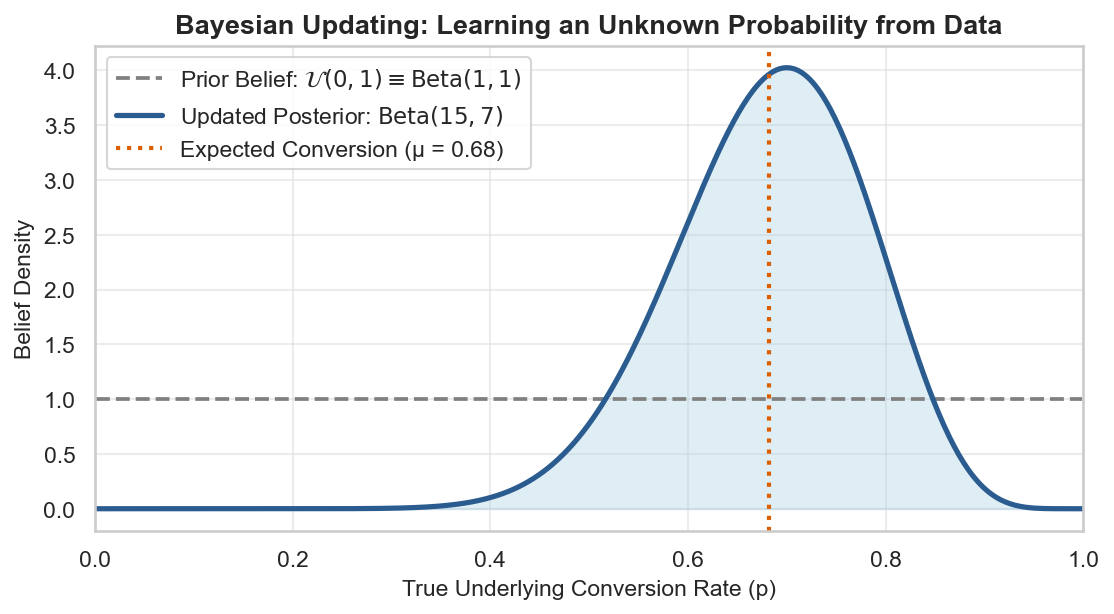

Posterior Mean Conversion Rate: 0.6818 (Observed 14/20 = 0.7000)


In [5]:
# Grid of candidate probabilities on [0, 1]
p_grid = np.linspace(0.001, 0.999, 400)

# 1. Uninformative Prior: Beta(1, 1) = Uniform(0, 1) [Zero observations]
prior_alpha, prior_beta = 1, 1
prior_pdf = stats.beta.pdf(p_grid, prior_alpha, prior_beta)

# 2. Observed Experiment: 14 conversions, 6 bounces out of 20 visitors
successes, failures = 14, 6

# 3. Analytical Bayesian Posterior: Beta(alpha + successes, beta + failures)
post_alpha = prior_alpha + successes  # 15
post_beta = prior_beta + failures  # 7
posterior_pdf = stats.beta.pdf(p_grid, post_alpha, post_beta)

plt.figure(figsize=(8.5, 4.2))
plt.plot(
    p_grid,
    prior_pdf,
    color="gray",
    linestyle="--",
    linewidth=1.8,
    label=r"Prior Belief: $\mathcal{U}(0, 1) \equiv \mathrm{Beta}(1, 1)$",
)
plt.plot(
    p_grid,
    posterior_pdf,
    color=PALETTE["primary"],
    linewidth=2.5,
    label=f"Updated Posterior: $\\text{{Beta}}({post_alpha}, {post_beta})$",
)
plt.fill_between(p_grid, posterior_pdf, color=PALETTE["fill"], alpha=0.35)

# Expected conversion rate: alpha / (alpha + beta)
expected_p = post_alpha / (post_alpha + post_beta)
plt.axvline(
    expected_p,
    color=PALETTE["secondary"],
    linestyle=":",
    linewidth=2,
    label=f"Expected Conversion (μ = {expected_p:.2f})",
)

plt.title("Bayesian Updating: Learning an Unknown Probability from Data", weight="bold")
plt.xlabel("True Underlying Conversion Rate (p)")
plt.ylabel("Belief Density")
plt.xlim(0, 1)
plt.legend(frameon=True)
plt.show()

print(f"Posterior Mean Conversion Rate: {expected_p:.4f} (Observed 14/20 = {successes/(successes+failures):.4f})")

## 2. Mathematical Definition

A continuous random variable $X$ follows a Beta distribution with shape parameters $\alpha$ and $\beta$, written:
$$X \sim \text{Beta}(\alpha, \beta)$$

### Parameters & Support
- **$\alpha > 0$**: Shape parameter (pseudo-count of successes).
- **$\beta > 0$**: Shape parameter (pseudo-count of failures).
- **Support**: Strictly bounded: $x \in [0, 1]$.

### Probability Density Function (PDF)
$$f(x) = \frac{1}{\text{B}(\alpha, \beta)} x^{\alpha - 1} (1 - x)^{\beta - 1} \quad \text{for } 0 \le x \le 1$$

### The Beta Function $\text{B}(\alpha, \beta)$
The normalizing constant is defined in terms of the Gamma function:
$$\text{B}(\alpha, \beta) = \frac{\Gamma(\alpha)\Gamma(\beta)}{\Gamma(\alpha + \beta)} = \int_{0}^{1} t^{\alpha - 1}(1 - t)^{\beta - 1} \, dt$$

### Cumulative Distribution Function (CDF)
$$F(x) = P(X \le x) = I_x(\alpha, \beta) = \frac{\text{B}(x; \alpha, \beta)}{\text{B}(\alpha, \beta)}$$
where $I_x(\alpha, \beta)$ is the regularized incomplete Beta function.

### SciPy Parameterization Convention
In `scipy.stats.beta(a, b)`:
- `a = alpha`
- `b = beta`

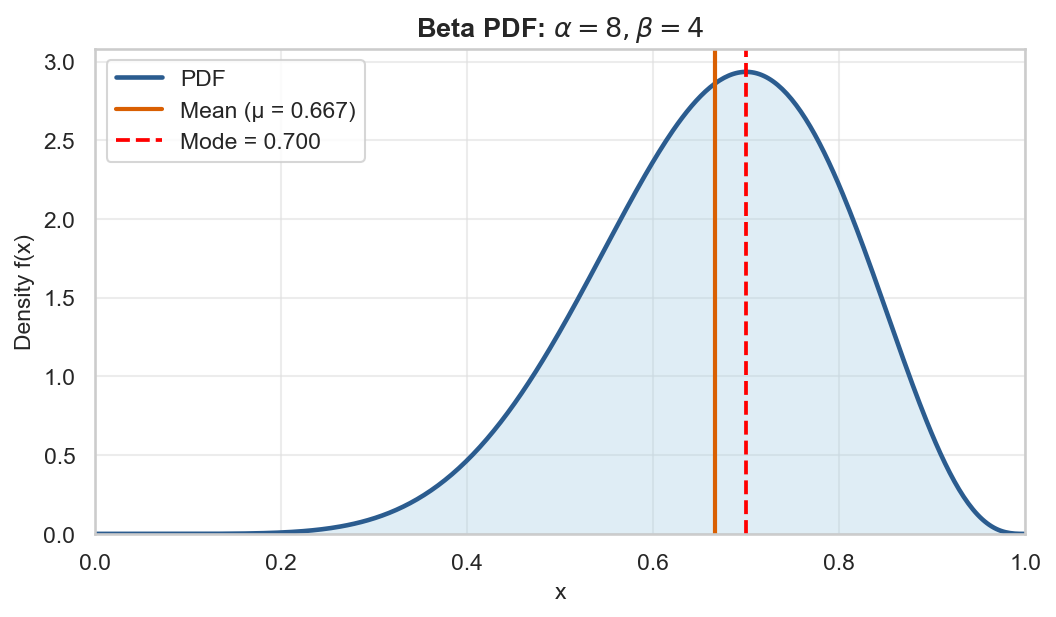

In [6]:
# Parameters: alpha = 8, beta = 4
a_param = 8.0
b_param = 4.0

x_eval = np.linspace(0.001, 0.999, 400)
pdf_vals = stats.beta.pdf(x_eval, a=a_param, b=b_param)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    x_eval,
    pdf_vals,
    title=f"Beta PDF: $\\alpha = {a_param:.0f}, \\beta = {b_param:.0f}$",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)

# Highlight Mean and Mode
mean_val = a_param / (a_param + b_param)
mode_val = (a_param - 1) / (a_param + b_param - 2)

ax.axvline(
    mean_val,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mean_val:.3f})",
)
ax.axvline(
    mode_val,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label=f"Mode = {mode_val:.3f}",
)
ax.legend(frameon=True)
ax.set_xlim(0, 1)
plt.show()

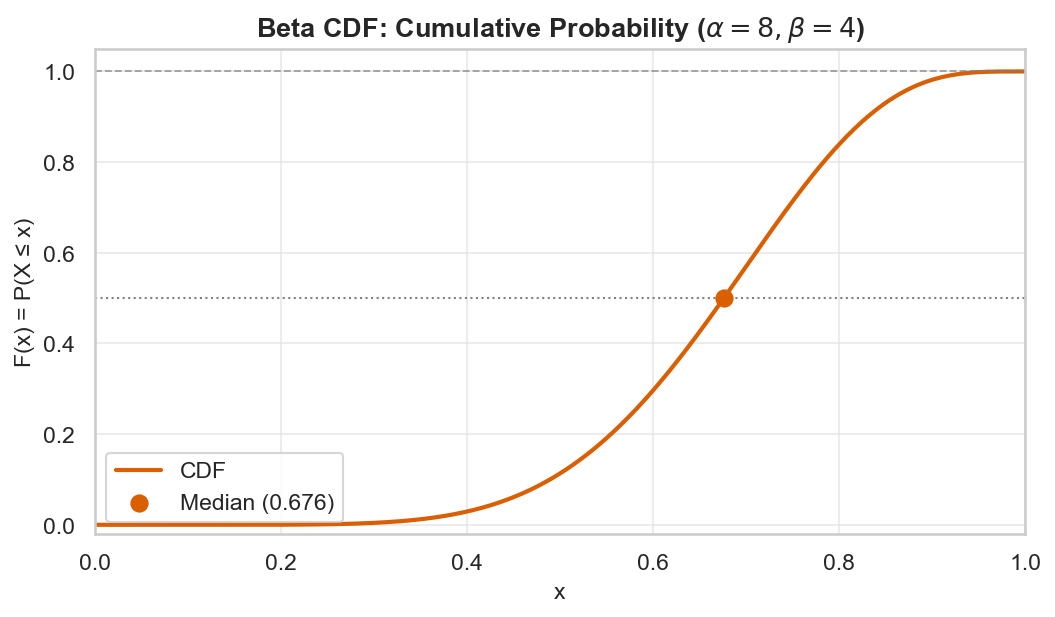

In [9]:
cdf_vals = stats.beta.cdf(x_eval, a=a_param, b=b_param)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    x_eval,
    cdf_vals,
    is_discrete=False,
    title = rf"Beta CDF: Cumulative Probability ($\alpha={a_param:.0f}, \beta={b_param:.0f}$)",
    xlabel="x",
    ylabel="F(x) = P(X ≤ x)",
    ax=ax,
)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
median_val = stats.beta.ppf(0.5, a=a_param, b=b_param)
ax.scatter([median_val], [0.5], color=PALETTE["secondary"], s=60, zorder=5, label=f"Median ({median_val:.3f})")
ax.legend(frameon=True)
ax.set_xlim(0, 1)
plt.show()

## 5. Simulation & Law of Large Numbers

### Generating Beta Variates from Gamma Variates:
To simulate $X \sim \text{Beta}(\alpha, \beta)$, algorithms generate two independent Gamma random variables:
$$G_1 \sim \text{Gamma}(\alpha, 1), \quad G_2 \sim \text{Gamma}(\beta, 1)$$
Then compute the ratio:
$$X = \frac{G_1}{G_1 + G_2} \sim \text{Beta}(\alpha, \beta)$$

By the **Law of Large Numbers**:
$$\bar{X}_N = \frac{1}{N}\sum_{i=1}^N X_i \xrightarrow{P} \mu = \frac{\alpha}{\alpha + \beta}$$

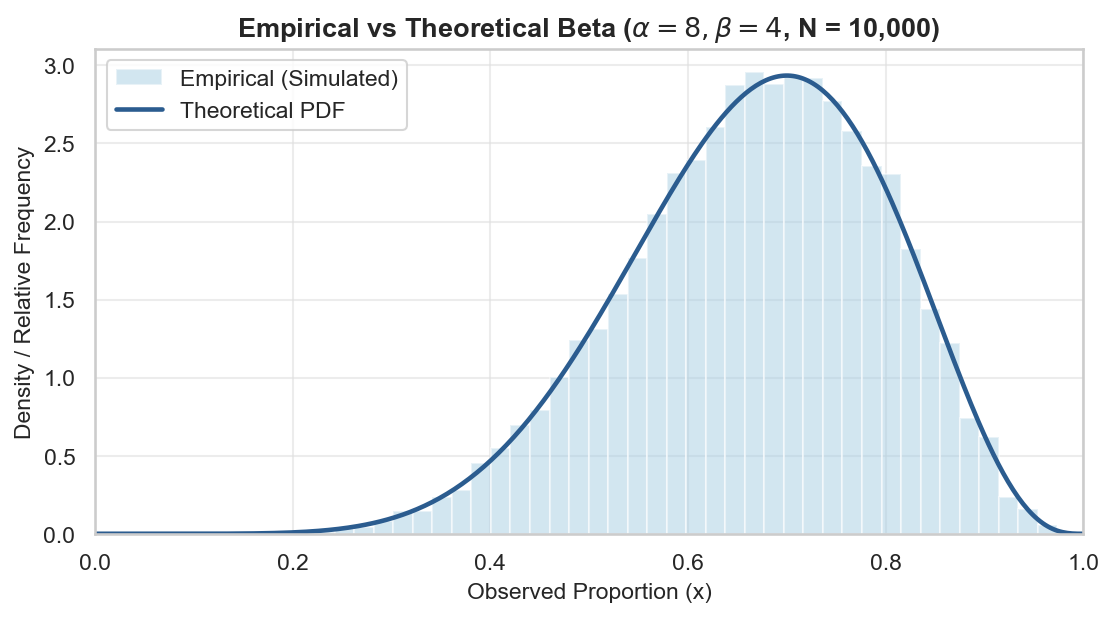

In [13]:
from utils.plotting import plot_sample_vs_theory

a_sim = 8.0
b_sim = 4.0
sample_size = 10000

mu_target = a_sim / (a_sim + b_sim)  # 2/3 ≈ 0.6667
var_target = (a_sim * b_sim) / (((a_sim + b_sim) ** 2) * (a_sim + b_sim + 1))  # 32 / (144 * 13) ≈ 0.01709

# Generate random Beta samples
samples_beta = stats.beta.rvs(a=a_sim, b=b_sim, size=sample_size, random_state=42)

# Theoretical curve
x_th = np.linspace(0.001, 0.999, 400)
pdf_th = stats.beta.pdf(x_th, a=a_sim, b=b_sim)

# Plot empirical histogram vs continuous PDF
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_sample_vs_theory(
    samples=samples_beta,
    x_theory=x_th,
    y_theory=pdf_th,
    is_discrete=False,
    title=rf"Empirical vs Theoretical Beta ($\alpha={a_sim:.0f}, \beta={b_sim:.0f}$, N = {sample_size:,})",
    xlabel="Observed Proportion (x)",
    ax=ax,
)
ax.set_xlim(0, 1)
plt.show()

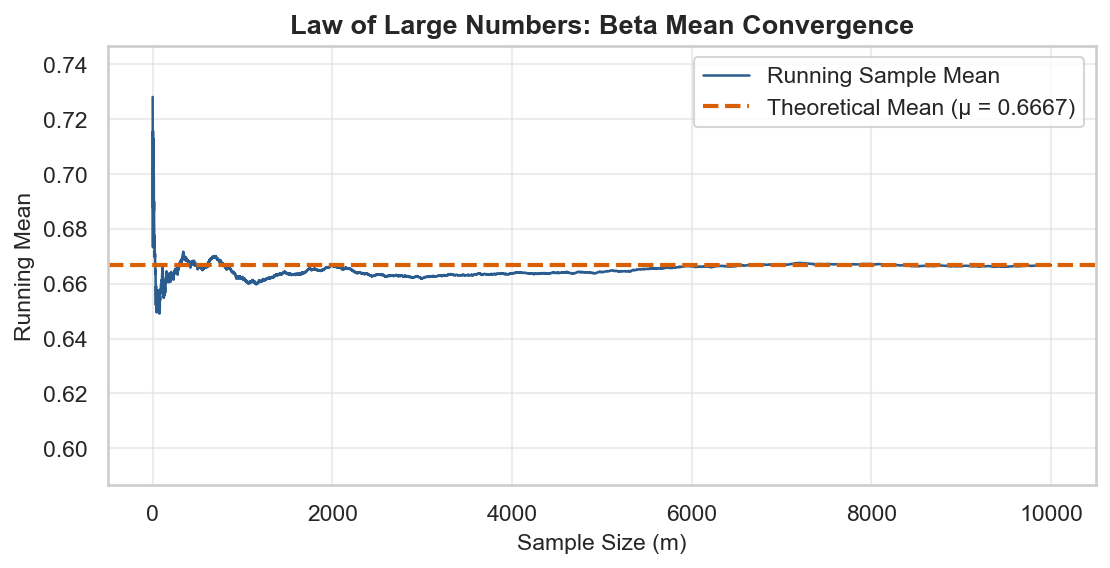

Sample Mean: 0.6668 (Theoretical: 0.6667)
Sample Var:  0.0169 (Theoretical: 0.0171)


In [14]:
# Running average convergence
running_beta_mean = np.cumsum(samples_beta) / np.arange(1, sample_size + 1)
plt.figure(figsize=(8.5, 3.8))
plt.plot(
    running_beta_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_target,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_target:.4f})",
)
plt.title("Law of Large Numbers: Beta Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Running Mean")
plt.ylim(mu_target - 0.08, mu_target + 0.08)
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean: {np.mean(samples_beta):.4f} (Theoretical: {mu_target:.4f})")
print(f"Sample Var:  {np.var(samples_beta, ddof=1):.4f} (Theoretical: {var_target:.4f})")

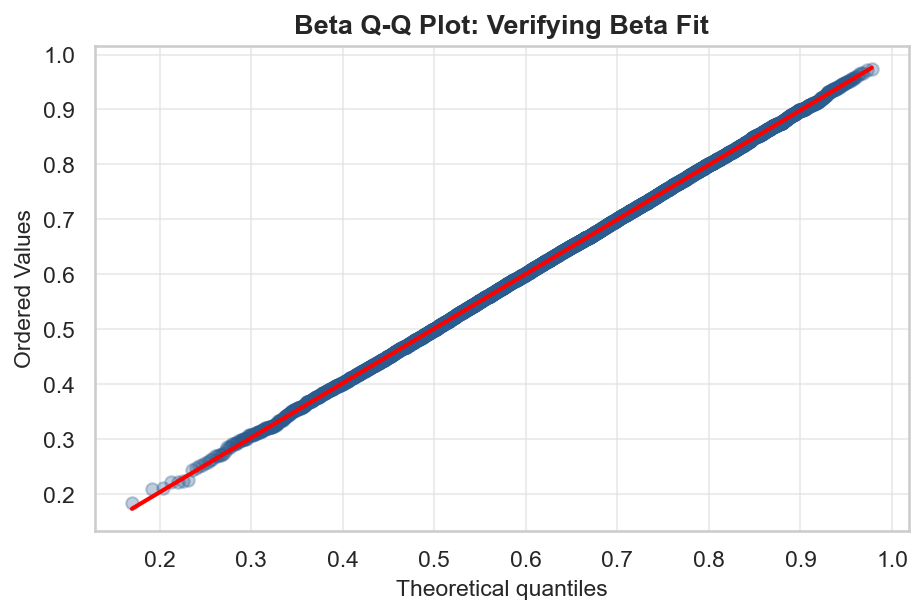

In [15]:
# Beta Q-Q Plot Diagnostic
fig, ax = plt.subplots(figsize=(7, 4.2))
stats.probplot(samples_beta, dist=stats.beta(a=a_sim, b=b_sim), plot=ax)

# Style Q-Q plot
ax.get_lines()[0].set_markerfacecolor(PALETTE["primary"])
ax.get_lines()[0].set_color(PALETTE["primary"])
ax.get_lines()[0].set_alpha(0.3)
ax.get_lines()[1].set_color("red")
ax.get_lines()[1].set_linewidth(2)

ax.set_title("Beta Q-Q Plot: Verifying Beta Fit", weight="bold")
plt.show()

## 6. Applied Real-World Use Case: Bayesian A/B Testing & Thompson Sampling

### Scenario
An e-commerce company is testing a redesigned checkout flow:
- **Control (A)**: $100$ visitors, $12$ conversions ($88$ bounces).
- **Variant (B)**: $120$ visitors, $22$ conversions ($98$ bounces).

Using uninformative uniform priors $\text{Beta}(1, 1)$, the posterior beliefs for the true conversion rates are:
$$p_A \sim \text{Beta}(1 + 12, 1 + 88) = \text{Beta}(13, 89) \quad (\mu_A = 12.7\%)$$
$$p_B \sim \text{Beta}(1 + 22, 1 + 98) = \text{Beta}(23, 99) \quad (\mu_B = 18.9\%)$$

### Core Decision Question:
***"What is the exact probability that Variant B is truly better than Control A ($P(p_B > p_A)$)?"***
In frequentist testing, you get a convoluted p-value. In Bayesian A/B testing, you compute the exact probability of winning directly by sampling from the Beta posteriors!

In [16]:
# Posterior parameters
a_A, b_A = 13, 89
a_B, b_B = 23, 99
n_draws = 100000

# Draw posterior samples for both conversion rates
draws_A = stats.beta.rvs(a=a_A, b=b_A, size=n_draws, random_state=42)
draws_B = stats.beta.rvs(a=a_B, b=b_B, size=n_draws, random_state=42)

# Compute probability that B beats A: P(p_B > p_A)
prob_B_beats_A = np.mean(draws_B > draws_A)

# Relative uplift: (p_B - p_A) / p_A
uplift_draws = (draws_B - draws_A) / draws_A
expected_uplift = np.mean(uplift_draws)

print("--- BAYESIAN A/B TEST REPORT ---")
print(f"Control A Expected Conversion: {np.mean(draws_A) * 100:.2f}% (95% CI: [{np.percentile(draws_A, 2.5)*100:.1f}%, {np.percentile(draws_A, 97.5)*100:.1f}%])")
print(f"Variant B Expected Conversion: {np.mean(draws_B) * 100:.2f}% (95% CI: [{np.percentile(draws_B, 2.5)*100:.1f}%, {np.percentile(draws_B, 97.5)*100:.1f}%])\n")
print(f"Probability that Variant B is Better: P(p_B > p_A) = {prob_B_beats_A * 100:.2f}%")
print(f"Expected Relative Conversion Lift:    +{expected_uplift * 100:.1f}%")

--- BAYESIAN A/B TEST REPORT ---
Control A Expected Conversion: 12.74% (95% CI: [7.0%, 19.8%])
Variant B Expected Conversion: 18.86% (95% CI: [12.5%, 26.2%])

Probability that Variant B is Better: P(p_B > p_A) = 89.96%
Expected Relative Conversion Lift:    +58.7%


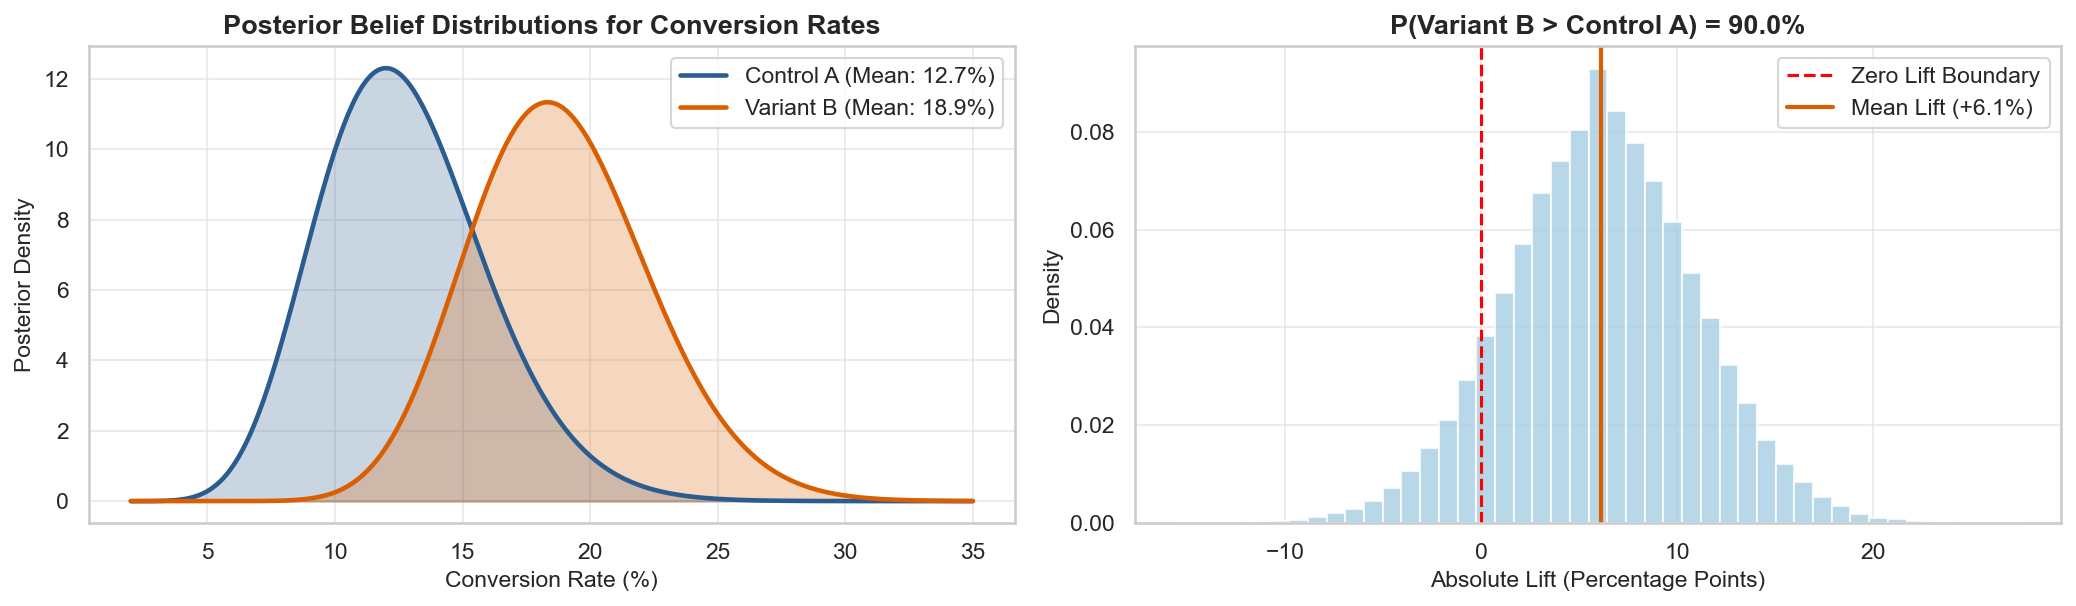

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
p_axis = np.linspace(0.02, 0.35, 400)

# Subplot 1: Overlapping Posterior Distributions
pdf_A = stats.beta.pdf(p_axis, a_A, b_A)
pdf_B = stats.beta.pdf(p_axis, a_B, b_B)

ax1.plot(p_axis * 100, pdf_A, color=PALETTE["primary"], linewidth=2.2, label=f"Control A (Mean: {a_A/(a_A+b_A)*100:.1f}%)")
ax1.fill_between(p_axis * 100, pdf_A, color=PALETTE["primary"], alpha=0.25)

ax1.plot(p_axis * 100, pdf_B, color=PALETTE["secondary"], linewidth=2.2, label=f"Variant B (Mean: {a_B/(a_B+b_B)*100:.1f}%)")
ax1.fill_between(p_axis * 100, pdf_B, color=PALETTE["secondary"], alpha=0.25)

ax1.set_title("Posterior Belief Distributions for Conversion Rates", weight="bold")
ax1.set_xlabel("Conversion Rate (%)")
ax1.set_ylabel("Posterior Density")
ax1.legend(frameon=True)

# Subplot 2: Difference / Lift Distribution
diff_draws = (draws_B - draws_A) * 100
ax2.hist(diff_draws, bins=45, density=True, color=PALETTE["fill"], edgecolor="white", alpha=0.8)
ax2.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Lift Boundary")
ax2.axvline(np.mean(diff_draws), color=PALETTE["secondary"], linestyle="-", linewidth=2, label=f"Mean Lift (+{np.mean(diff_draws):.1f}%)")

ax2.set_title(f"P(Variant B > Control A) = {prob_B_beats_A * 100:.1f}%", weight="bold")
ax2.set_xlabel("Absolute Lift (Percentage Points)")
ax2.set_ylabel("Density")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given continuous observations $x_1, x_2, \dots, x_N \in (0, 1)$:

### The Log-Likelihood Function
$$\ln L(\alpha, \beta) = N \ln \Gamma(\alpha + \beta) - N \ln \Gamma(\alpha) - N \ln \Gamma(\beta) + (\alpha - 1)\sum_{i=1}^N \ln(x_i) + (\beta - 1)\sum_{i=1}^N \ln(1 - x_i)$$

### The Digamma System:
Differentiating with respect to $\alpha$ and $\beta$ yields two coupled equations involving the digamma function $\psi(z)$:
$$\psi(\alpha) - \psi(\alpha + \beta) = \frac{1}{N}\sum_{i=1}^{N}\ln(x_i)$$
$$\psi(\beta) - \psi(\alpha + \beta) = \frac{1}{N}\sum_{i=1}^{N}\ln(1 - x_i)$$
This system has no closed-form solution and must be solved using numerical optimization.

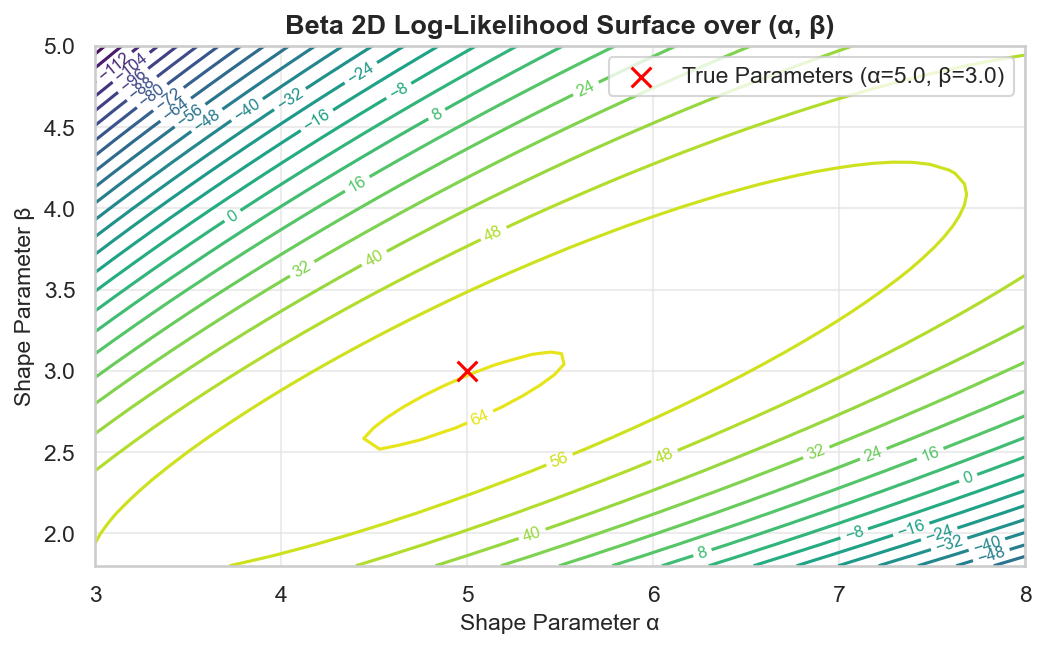

In [18]:
# True parameters
alpha_true = 5.0
beta_true = 3.0
N_obs = 150

# Generate synthetic observations on (0, 1)
data_beta = stats.beta.rvs(
    a=alpha_true, b=beta_true, size=N_obs, random_state=88
)

# 2D Grid search for visualization
a_cand = np.linspace(3.0, 8.0, 50)
b_cand = np.linspace(1.8, 5.0, 50)
A_grid, B_grid = np.meshgrid(a_cand, b_cand)


def beta_2d_log_lik(a_val, b_val, data):
    return np.sum(stats.beta.logpdf(data, a=a_val, b=b_val))


log_lik_surface = np.zeros_like(A_grid)
for i in range(A_grid.shape[0]):
    for j in range(A_grid.shape[1]):
        log_lik_surface[i, j] = beta_2d_log_lik(
            A_grid[i, j], B_grid[i, j], data_beta
        )

plt.figure(figsize=(8, 4.5))
contours = plt.contour(
    A_grid, B_grid, log_lik_surface, levels=25, cmap="viridis"
)
plt.clabel(contours, inline=True, fontsize=8)
plt.scatter(
    [alpha_true],
    [beta_true],
    color="red",
    s=90,
    zorder=5,
    marker="x",
    label=f"True Parameters (α={alpha_true}, β={beta_true})",
)

plt.title("Beta 2D Log-Likelihood Surface over (α, β)", weight="bold")
plt.xlabel("Shape Parameter α")
plt.ylabel("Shape Parameter β")
plt.legend(frameon=True)
plt.show()

In [19]:
from scipy.optimize import minimize


# Negative Log-Likelihood objective function
def neg_log_lik_beta(params, data):
    a_val, b_val = params
    if a_val <= 0.05 or b_val <= 0.05:
        return 1e9
    return -np.sum(stats.beta.logpdf(data, a=a_val, b=b_val))


# Method of Moments initial guess
x_bar = np.mean(data_beta)
s_sq = np.var(data_beta, ddof=1)
common_factor = (x_bar * (1 - x_bar) / s_sq) - 1.0
a_init = np.clip(x_bar * common_factor, 0.5, 20.0)
b_init = np.clip((1 - x_bar) * common_factor, 0.5, 20.0)

# Optimize
res = minimize(
    neg_log_lik_beta,
    x0=[a_init, b_init],
    args=(data_beta,),
    bounds=[(0.1, 50.0), (0.1, 50.0)],
)
a_mle, b_mle = res.x

print("--- BETA MLE ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Sample Mean Proportion:     {x_bar:.4f}")
print(f"Sample Variance:            {s_sq:.4f}\n")
print(f"Parameter | True Value | MLE Estimate")
print("-" * 38)
print(f"α (alpha) | {alpha_true:10.4f} | {a_mle:10.4f}")
print(f"β (beta)  | {beta_true:10.4f} | {b_mle:10.4f}")
print(
    f"\nEstimated Model Mean:  {a_mle / (a_mle + b_mle):.4f} (matches sample mean {x_bar:.4f})"
)

--- BETA MLE ESTIMATION RESULTS ---
Sample Size (N):            150
Sample Mean Proportion:     0.6388
Sample Variance:            0.0266

Parameter | True Value | MLE Estimate
--------------------------------------
α (alpha) |     5.0000 |     4.9648
β (beta)  |     3.0000 |     2.8067

Estimated Model Mean:  0.6388 (matches sample mean 0.6388)


## 8. Related Distributions & Summary

The Beta distribution unites continuous proportions with discrete counts:

1. **Uniform Distribution ($\text{Beta}(1, 1)$)**:
   - When $\alpha = 1, \beta = 1$, the Beta distribution is strictly identical to $\mathcal{U}(0, 1)$.
2. **Bernoulli & Binomial (Conjugate Updating)**:
   - Beta is the **conjugate prior** for the Bernoulli/Binomial likelihood.
   - If prior is $\text{Beta}(\alpha, \beta)$ and you observe $k$ successes in $n$ trials, the posterior is analytically:
     $$\text{Posterior} \sim \text{Beta}(\alpha + k, \, \beta + n - k)$$
3. **Dirichlet Distribution (Multivariate Beta)**:
   - Generalizes the 2-parameter Beta distribution to $K > 2$ categorical probability vectors (used in Latent Dirichlet Allocation for NLP topic modeling).
4. **Order Statistics of Uniform Random Variables**:
   - If you draw $n$ independent $\mathcal{U}(0, 1)$ variables and sort them $U_{(1)} \le U_{(2)} \le \dots \le U_{(n)}$, the $k$-th smallest value follows:
     $$U_{(k)} \sim \text{Beta}(k, \, n - k + 1)$$

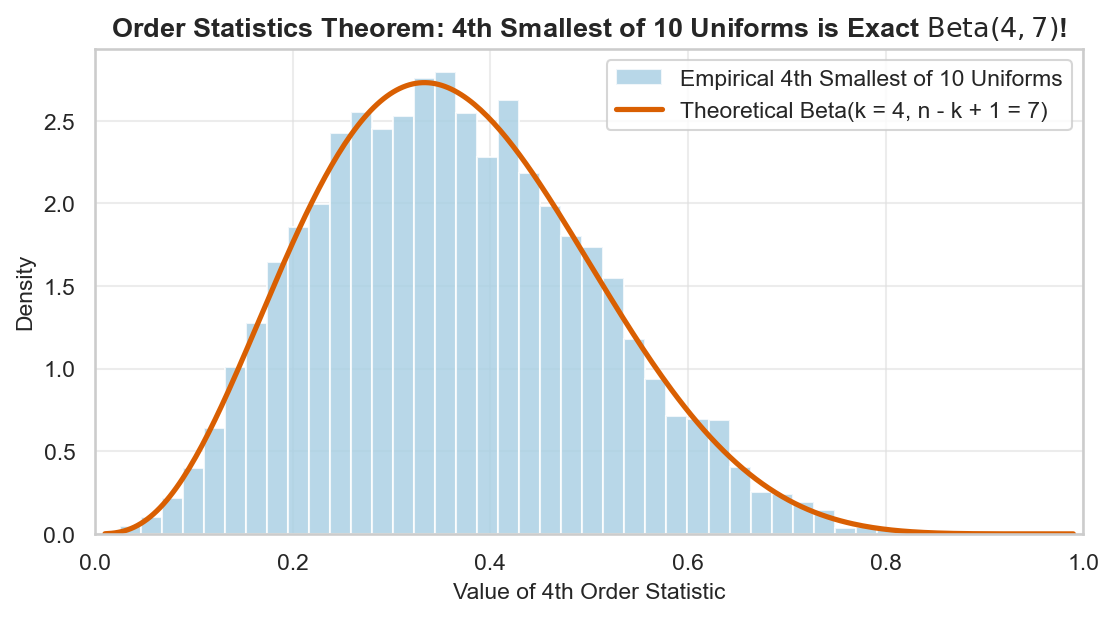

Sample Mean of 4th Smallest:      0.3648
Theoretical Mean k / (n + 1):     0.3636


In [21]:
# Proving that the k-th order statistic of n Uniform draws is Beta(k, n - k + 1)
n_draws_u = 10
k_order = 4
n_trials_order = 10000

rng = np.random.default_rng(42)

# 1. Generate 10 uniform draws per trial: Shape (10000, 10)
u_matrix = rng.uniform(0, 1, size=(n_trials_order, n_draws_u))

# 2. Sort each trial across columns
u_sorted = np.sort(u_matrix, axis=1)

# 3. Extract the 4th smallest element (index 3): U_(4)
fourth_smallest = u_sorted[:, k_order - 1]

# 4. Compare against theoretical Beta(k = 4, n - k + 1 = 7)
x_order = np.linspace(0.01, 0.99, 300)
pdf_beta_order = stats.beta.pdf(x_order, a=k_order, b=n_draws_u - k_order + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(
    fourth_smallest,
    bins=40,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label=f"Empirical 4th Smallest of {n_draws_u} Uniforms",
)
ax.plot(
    x_order,
    pdf_beta_order,
    color=PALETTE["secondary"],
    linewidth=2.5,
    label=f"Theoretical Beta(k = {k_order}, n - k + 1 = {n_draws_u - k_order + 1})",
)

ax.set_title(
    f"Order Statistics Theorem: 4th Smallest of 10 Uniforms is Exact $\\text{{Beta}}(4, 7)$!",
    weight="bold",
)
ax.set_xlabel("Value of 4th Order Statistic")
ax.set_ylabel("Density")
ax.set_xlim(0, 1)
ax.legend(frameon=True)
plt.show()

print(f"Sample Mean of 4th Smallest:      {np.mean(fourth_smallest):.4f}")
print(f"Theoretical Mean k / (n + 1):     {k_order / (n_draws_u + 1):.4f}")

### Summary Card: Beta Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Beta}(\alpha, \beta)$ |
| **Parameters** | $\alpha > 0$ (pseudo-successes), $\beta > 0$ (pseudo-failures) |
| **Support** | $x \in [0, 1]$ |
| **PDF** | $f(x) = \frac{1}{\text{B}(\alpha, \beta)} x^{\alpha - 1}(1 - x)^{\beta - 1}$ |
| **CDF** | $F(x) = I_x(\alpha, \beta)$ (Regularized Incomplete Beta) |
| **Mean ($\mu$)** | $\frac{\alpha}{\alpha + \beta}$ |
| **Variance ($\sigma^2$)** | $\frac{\alpha \beta}{(\alpha + \beta)^2(\alpha + \beta + 1)} = \frac{\mu(1 - \mu)}{\alpha + \beta + 1}$ |
| **Mode** | $\frac{\alpha - 1}{\alpha + \beta - 2}$ for $\alpha, \beta > 1$ |
| **Skewness ($\gamma_1$)** | $\frac{2(\beta - \alpha)\sqrt{\alpha + \beta + 1}}{(\alpha + \beta + 2)\sqrt{\alpha \beta}}$ |
| **Conjugate Prior** | Bernoulli & Binomial likelihoods |
| **Key Property** | Bounded strictly on $[0, 1]$; Order statistic $U_{(k)} \sim \text{Beta}(k, n - k + 1)$ |
| **Key Use Cases** | Bayesian A/B testing, Thompson sampling (multi-armed bandits), conversion rates, click-through rates |